In [1]:
import sklearn
print(sklearn.__version__)

1.7.2


In [2]:
import numpy as np
import pandas as pd

## Import Of Libraries

In [3]:
# First, we import our libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

## Importation Of File

In [4]:
#import file
titanic_data = pd.read_csv('data/titanic.csv')
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [5]:
# You can also get this data from seaborn
import seaborn as sns
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Data Preprocessing

In [6]:
titanic_data.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [7]:
titanic_data["Survived"].value_counts()

Survived
0    545
1    342
Name: count, dtype: int64

In [8]:
titanic_data.isnull().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
PaCh        0
Fare        0
dtype: int64

## Data Visualization

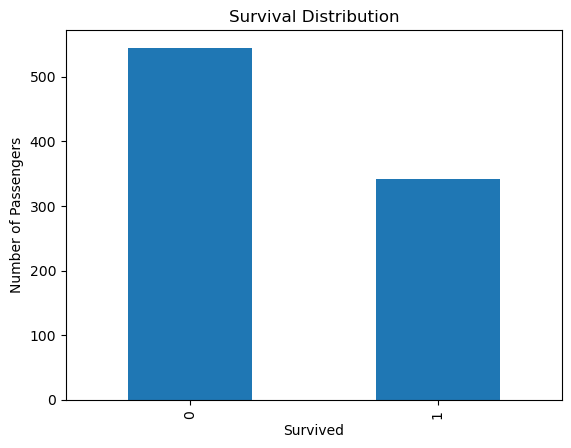

In [9]:
titanic_data["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

In [10]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare']
target = 'Survived'

In [11]:
X = titanic_data[features].copy()
y = titanic_data[target].copy()

In [12]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500


In [13]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [14]:
X['Sex'] = X['Sex'].apply(lambda x: 1 if x == 'female' else 0)

In [15]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,3,1,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [17]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (709, 6)
Testing data: (178, 6)


In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train logistic regression model using the processed titanic data

In [20]:
# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [21]:
logistic_predictions = logistic_model.predict(X_test_scaled)
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)
print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.7696629213483146


In [22]:
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       0.80      0.83      0.81       109
           1       0.71      0.68      0.70        69

    accuracy                           0.77       178
   macro avg       0.76      0.75      0.76       178
weighted avg       0.77      0.77      0.77       178



## Train decision tree model using the processed titanic data

In [25]:
# Train Decision Tree
tree_model = DecisionTreeClassifier(
    random_state=42
)
tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.7471910112359551


In [27]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       0.79      0.80      0.79       109
           1       0.68      0.67      0.67        69

    accuracy                           0.75       178
   macro avg       0.73      0.73      0.73       178
weighted avg       0.75      0.75      0.75       178



## Train random forest model using the processed titanic data

In [28]:
# Train Random Forest
forest_model = RandomForestClassifier(
    random_state=42
)
forest_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
forest_predictions = forest_model.predict(X_test)
forest_accuracy = accuracy_score(
    y_test,
    forest_predictions
)
print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.7752808988764045


In [30]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.81      0.83      0.82       109
           1       0.72      0.70      0.71        69

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.78      0.77       178



## Comparing the  three model accuracy to known the one that do better

In [31]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ]
    })
results

,Model,Accuracy
0,Logistic Regression,0.769663
1,Decision Tree,0.747191
2,Random Forest,0.775281


In [32]:
results.sort_values(
by="Accuracy",
ascending=False
)


,Model,Accuracy
2,Random Forest,0.775281
0,Logistic Regression,0.769663
1,Decision Tree,0.747191


## visualization of the three model accuracy

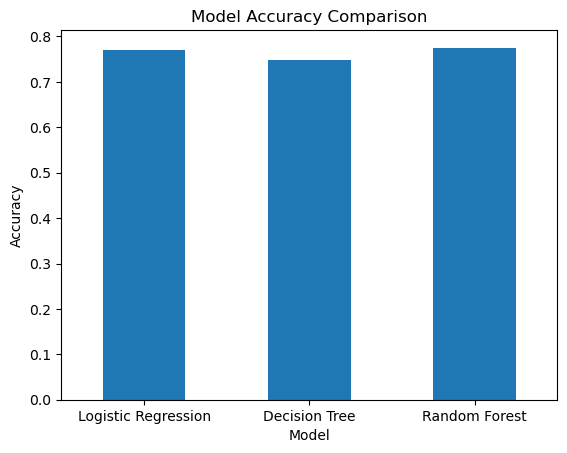

In [33]:
results.plot(
x="Model",
y="Accuracy",
kind="bar",
legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

## Confusion Matrix

In [34]:
cm = confusion_matrix(
y_test,
logistic_predictions
)
print(cm)

[[90 19]
 [22 47]]


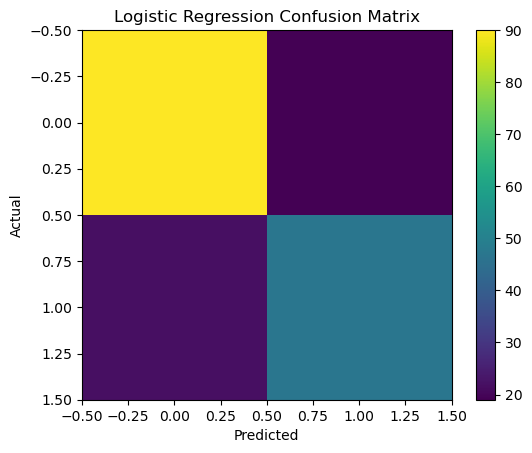

In [35]:
plt.imshow(cm)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

##  Tune the Decision Tree

In [38]:
# Tune the Decision Tree
tree_params = {
"max_depth": [2, 3, 4, 5, 6, 8, 10],
}
tree_grid = GridSearchCV(
DecisionTreeClassifier(random_state=42),
tree_params,
cv=5,
scoring="accuracy"
)
tree_grid.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'max_depth': [2, 3, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [39]:
print("Best Parameters:")
print(tree_grid.best_params_)
print("Best Cross-Validation Accuracy:")
print(tree_grid.best_score_)

Best Parameters:
{'max_depth': 4}
Best Cross-Validation Accuracy:
0.818060133852762


In [40]:
# Evaluate the Tuned Decision Tree
best_tree = tree_grid.best_estimator_
tuned_tree_predictions = best_tree.predict(X_test)
tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_predictions
)
print("Tuned Decision Tree Accuracy:", tuned_tree_accuracy)

Tuned Decision Tree Accuracy: 0.8033707865168539


##  Tune the Random Forest

In [45]:
# Tune the Random Forest
forest_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10]
}
forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_params,
    cv=5,
    scoring="accuracy"
)
forest_grid.fit(X_train, y_train)


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [49]:
print("Best Parameters:")
print(forest_grid.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(forest_grid.best_score_)

Best Parameters:
{'max_depth': 7, 'n_estimators': 50}

Best Cross-Validation Accuracy:
0.8392168614524025


In [50]:
def predict_survival(name, Pclass, Sex, Age, SibSp, PaCh, Fare):
    """
    Predict survival using our model
    """
    input_data = pd.DataFrame({
        'Pclass': [Pclass],
        'Sex': [Sex],
        'Age': [Age],
        'SibSp': [SibSp],
        'PaCh': [PaCh],
        'Fare': [Fare]
    })    
    
    prediction = best_forest.predict(input_data)[0]
    probabilities = best_forest.predict_proba(input_data)[0] # to explain
    if prediction == 0:
        result = f'Wooo 😮 {name.title()}, you Died 😢'

    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁'
        
    return result, probabilities

In [52]:
print(predict_survival('Arafat', Pclass=3, Sex=1, Age=25.0, SibSp=0, PaCh=0, Fare=100))

('Cheers 🥂 Arafat, you Survived 😁', array([0.37671003, 0.62328997]))
